In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats

In [2]:
short = pd.read_csv(
    "data/processed/short_with_regime.csv",
    index_col=0,
    parse_dates=True
)

medium = pd.read_csv(
    "data/processed/medium_with_regime.csv",
    index_col=0,
    parse_dates=True
)

long = pd.read_csv(
    "data/processed/long_with_regime.csv",
    index_col=0,
    parse_dates=True
)

In [3]:
short.head()

,SPY,TLT,GLD,BTC-USD,Regime
2015-02-03,0.012082,-0.017108,-0.007482,-0.021634,Normal
2015-02-04,-0.006297,0.011303,0.009490,0.012572,Normal
2015-02-05,0.007191,0.000838,0.007487,-0.036156,Normal
2015-02-06,-0.006461,-0.007030,-0.020922,0.029333,Normal
2015-02-09,-0.008716,0.007205,0.009437,-0.009858,Normal


In [4]:
TRAIN_END = "2022-12-31"

In [5]:
short_train = short.loc[:TRAIN_END].copy()
medium_train = medium.loc[:TRAIN_END].copy()
long_train = long.loc[:TRAIN_END].copy()

In [6]:
ASSETS = [
    "SPY",
    "TLT",
    "GLD",
    "BTC-USD"
]

In [7]:
weights = np.array([
    0.25,
    0.25,
    0.25,
    0.25
])

In [8]:
print("Weight sum:", weights.sum())

Weight sum: 1.0


In [9]:
datasets = {
    
    "Short_Normal": (
        short_train[
            short_train["Regime"] == "Normal"
        ][ASSETS]
    ),
    
    "Short_Stress": (
        short_train[
            short_train["Regime"] == "Stress"
        ][ASSETS]
    ),
    
    "Medium_Normal": (
        medium_train[
            medium_train["Regime"] == "Normal"
        ][ASSETS]
    ),
    
    "Medium_Stress": (
        medium_train[
            medium_train["Regime"] == "Stress"
        ][ASSETS]
    ),
    
    "Long_Normal": (
        long_train[
            long_train["Regime"] == "Normal"
        ][ASSETS]
    ),
    
    "Long_Stress": (
        long_train[
            long_train["Regime"] == "Stress"
        ][ASSETS]
    )
}

In [10]:
for name, df in datasets.items():
    print(name, df.shape)

Short_Normal (1495, 4)
Short_Stress (498, 4)
Medium_Normal (1495, 4)
Medium_Stress (498, 4)
Long_Normal (1495, 4)
Long_Stress (498, 4)


In [11]:
portfolio_series = {}

for name, df in datasets.items():
    
    portfolio_series[name] = (
        df[ASSETS].values @ weights
    )

In [12]:
portfolio_series["Short_Normal"][:10]

array([-0.00853546,  0.00676694, -0.00515998, -0.00126988, -0.00048295,
       -0.00189227, -0.00574192,  0.00185872,  0.01133338, -0.00179654])

In [13]:
def calculate_risk(returns):
    
    returns = np.asarray(returns)
    
    var_95_threshold = np.quantile(
        returns,
        0.05
    )
    
    var_99_threshold = np.quantile(
        returns,
        0.01
    )
    
    es_975_threshold = np.quantile(
        returns,
        0.025
    )
    
    var_95 = -var_95_threshold
    var_99 = -var_99_threshold
    
    es_975 = -returns[
        returns <= es_975_threshold
    ].mean()
    
    return {
        "VaR_95": var_95,
        "VaR_99": var_99,
        "ES_97.5": es_975
    }

In [14]:
historical_risk_results = []

for name, series in portfolio_series.items():
    
    risk = calculate_risk(series)
    
    risk["Dataset"] = name
    risk["Model"] = "Historical"
    risk["N"] = len(series)
    
    historical_risk_results.append(
        risk
    )

historical_risk = pd.DataFrame(
    historical_risk_results
)

historical_risk

,VaR_95,VaR_99,ES_97.5,Dataset,Model,N
0,0.015956,0.028625,0.029446,Short_Normal,Historical,1495
1,0.018235,0.034265,0.039571,Short_Stress,Historical,498
2,0.008190,0.012675,0.012858,Medium_Normal,Historical,1495
3,0.009813,0.022494,0.020600,Medium_Stress,Historical,498
4,0.004574,0.005852,0.005737,Long_Normal,Historical,1495
5,0.003969,0.011475,0.010506,Long_Stress,Historical,498


In [15]:
def pseudo_observation_matrix(df):
    
    n = len(df)
    
    U = np.zeros(
        shape=df.shape
    )
    
    for j, column in enumerate(df.columns):
        
        ranks = stats.rankdata(
            df[column],
            method="average"
        )
        
        U[:, j] = (
            ranks / (n + 1.0)
        )
    
    return U

In [16]:
U_test = pseudo_observation_matrix(
    datasets["Short_Normal"]
)

print(U_test.shape)

print(
    U_test.min(),
    U_test.max()
)

(1495, 4)
0.0006684491978609625 0.9993315508021391


In [17]:
def kendall_correlation_matrix(df):
    
    d = df.shape[1]
    
    R = np.eye(d)
    
    for i in range(d):
        
        for j in range(i + 1, d):
            
            tau, _ = stats.kendalltau(
                df.iloc[:, i],
                df.iloc[:, j]
            )
            
            rho = np.sin(
                np.pi * tau / 2
            )
            
            R[i, j] = rho
            R[j, i] = rho
    
    return R

In [18]:
def nearest_positive_definite_correlation(R):
    
    R = np.asarray(R)
    
    eigenvalues, eigenvectors = np.linalg.eigh(
        R
    )
    
    eigenvalues = np.clip(
        eigenvalues,
        1e-6,
        None
    )
    
    R_pd = (
        eigenvectors
        @ np.diag(eigenvalues)
        @ eigenvectors.T
    )
    
    scale = np.sqrt(
        np.diag(R_pd)
    )
    
    R_corr = (
        R_pd
        /
        np.outer(scale, scale)
    )
    
    np.fill_diagonal(
        R_corr,
        1.0
    )
    
    return R_corr

In [19]:
R_test = kendall_correlation_matrix(
    datasets["Short_Normal"]
)

R_test = nearest_positive_definite_correlation(
    R_test
)

pd.DataFrame(
    R_test,
    index=ASSETS,
    columns=ASSETS
)

,SPY,TLT,GLD,BTC-USD
SPY,1.000000,-0.226171,-0.001355,0.069763
TLT,-0.226171,1.000000,0.373521,0.011659
GLD,-0.001355,0.373521,1.000000,0.080838
BTC-USD,0.069763,0.011659,0.080838,1.000000


In [20]:
def simulate_gaussian_copula(
    R,
    n_simulations=10000,
    seed=42
):
    
    rng = np.random.default_rng(
        seed
    )
    
    z = rng.multivariate_normal(
        mean=np.zeros(
            R.shape[0]
        ),
        cov=R,
        size=n_simulations
    )
    
    U = stats.norm.cdf(z)
    
    return U

In [21]:
def inverse_empirical_marginals(
    U,
    historical_df
):
    
    simulated_returns = np.zeros_like(
        U
    )
    
    for j, asset in enumerate(
        historical_df.columns
    ):
        
        simulated_returns[:, j] = np.quantile(
            historical_df[asset].values,
            U[:, j]
        )
    
    return simulated_returns

In [22]:
example_df = datasets[
    "Short_Normal"
]

R_example = kendall_correlation_matrix(
    example_df
)

R_example = nearest_positive_definite_correlation(
    R_example
)

U_gaussian = simulate_gaussian_copula(
    R_example,
    n_simulations=10000,
    seed=42
)

sim_gaussian = inverse_empirical_marginals(
    U_gaussian,
    example_df
)

print(sim_gaussian.shape)

(10000, 4)


In [23]:
portfolio_gaussian = (
    sim_gaussian @ weights
)

calculate_risk(
    portfolio_gaussian
)

{'VaR_95': np.float64(0.016922636952443667),
 'VaR_99': np.float64(0.02807910752536611),
 'ES_97.5': np.float64(0.029601723345572685)}

In [24]:
def multivariate_t_copula_loglik(
    U,
    R,
    nu
):
    
    X = stats.t.ppf(
        U,
        df=nu
    )
    
    joint = stats.multivariate_t.logpdf(
        X,
        loc=np.zeros(
            U.shape[1]
        ),
        shape=R,
        df=nu
    )
    
    marginal = np.sum(
        stats.t.logpdf(
            X,
            df=nu
        ),
        axis=1
    )
    
    copula_loglik = (
        joint - marginal
    )
    
    return np.sum(
        copula_loglik
    )

In [25]:
def estimate_t_degrees_of_freedom(
    df,
    R
):
    
    U = pseudo_observation_matrix(
        df
    )
    
    candidate_nu = range(
        3,
        31
    )
    
    results = []
    
    for nu in candidate_nu:
        
        loglik = multivariate_t_copula_loglik(
            U,
            R,
            nu
        )
        
        results.append({
            "nu": nu,
            "loglik": loglik
        })
    
    results_df = pd.DataFrame(
        results
    )
    
    best_row = results_df.loc[
        results_df["loglik"].idxmax()
    ]
    
    return (
        float(best_row["nu"]),
        results_df
    )

In [26]:
best_nu, nu_results = (
    estimate_t_degrees_of_freedom(
        example_df,
        R_example
    )
)

print(
    "Best nu:",
    best_nu
)

nu_results.head()

Best nu: 13.0


,nu,loglik
0,3,-4.015627
1,4,81.287671
2,5,118.245182
3,6,136.674478
4,7,146.678485


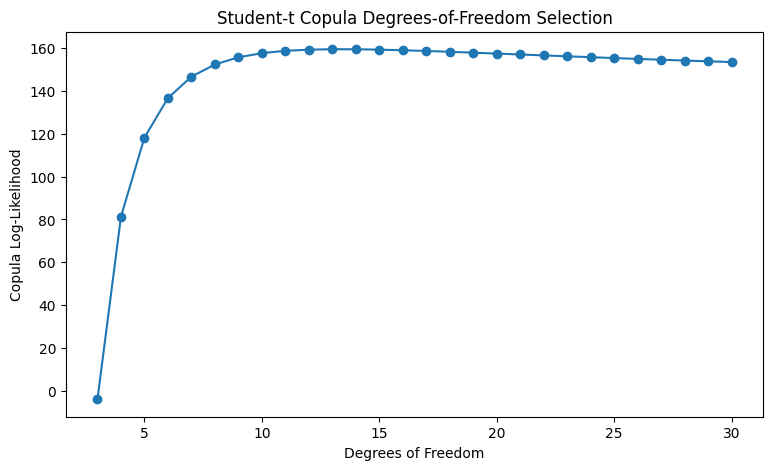

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    nu_results["nu"],
    nu_results["loglik"],
    marker="o"
)

plt.xlabel(
    "Degrees of Freedom"
)

plt.ylabel(
    "Copula Log-Likelihood"
)

plt.title(
    "Student-t Copula Degrees-of-Freedom Selection"
)

plt.show()

In [28]:
def simulate_t_copula(
    R,
    nu,
    n_simulations=10000,
    seed=42
):
    
    rng = np.random.default_rng(
        seed
    )
    
    X = stats.multivariate_t.rvs(
        loc=np.zeros(
            R.shape[0]
        ),
        shape=R,
        df=nu,
        size=n_simulations,
        random_state=rng
    )
    
    U = stats.t.cdf(
        X,
        df=nu
    )
    
    return U

In [29]:
U_t = simulate_t_copula(
    R_example,
    best_nu,
    n_simulations=10000,
    seed=42
)

sim_t = inverse_empirical_marginals(
    U_t,
    example_df
)

portfolio_t = (
    sim_t @ weights
)

calculate_risk(
    portfolio_t
)

{'VaR_95': np.float64(0.016488562377976156),
 'VaR_99': np.float64(0.02809113206242423),
 'ES_97.5': np.float64(0.029223999812067417)}

In [30]:
def estimate_portfolio_risk_models(
    df,
    weights,
    n_simulations=10000,
    seed=42
):
    
    R = kendall_correlation_matrix(
        df
    )
    
    R = nearest_positive_definite_correlation(
        R
    )
    
    # -----------------
    # Gaussian Copula
    # -----------------
    
    U_gaussian = simulate_gaussian_copula(
        R,
        n_simulations=n_simulations,
        seed=seed
    )
    
    gaussian_returns = inverse_empirical_marginals(
        U_gaussian,
        df
    )
    
    gaussian_portfolio = (
        gaussian_returns @ weights
    )
    
    gaussian_risk = calculate_risk(
        gaussian_portfolio
    )
    
    
    # -----------------
    # Student-t Copula
    # -----------------
    
    best_nu, _ = estimate_t_degrees_of_freedom(
        df,
        R
    )
    
    U_t = simulate_t_copula(
        R,
        best_nu,
        n_simulations=n_simulations,
        seed=seed
    )
    
    t_returns = inverse_empirical_marginals(
        U_t,
        df
    )
    
    t_portfolio = (
        t_returns @ weights
    )
    
    t_risk = calculate_risk(
        t_portfolio
    )
    
    
    return {
        "Gaussian": gaussian_risk,
        "Student-t": t_risk,
        "t_nu": best_nu,
        "Correlation_Matrix": R
    }

In [31]:
example_result = estimate_portfolio_risk_models(
    datasets["Short_Normal"],
    weights,
    n_simulations=10000,
    seed=42
)

example_result["Gaussian"]

{'VaR_95': np.float64(0.016922636952443667),
 'VaR_99': np.float64(0.02807910752536611),
 'ES_97.5': np.float64(0.029601723345572685)}

In [32]:
example_result["Student-t"]

{'VaR_95': np.float64(0.016488562377976156),
 'VaR_99': np.float64(0.02809113206242423),
 'ES_97.5': np.float64(0.029223999812067417)}

In [33]:
print(
    "Estimated t degrees of freedom:",
    example_result["t_nu"]
)

Estimated t degrees of freedom: 13.0


In [34]:
model_risk_results = []

t_nu_results = []

for dataset_name, df in datasets.items():
    
    print(
        "Processing:",
        dataset_name
    )
    
    result = estimate_portfolio_risk_models(
        df,
        weights,
        n_simulations=10000,
        seed=42
    )
    
    
    gaussian_row = {
        "Dataset": dataset_name,
        "Model": "Gaussian Copula",
        **result["Gaussian"]
    }
    
    model_risk_results.append(
        gaussian_row
    )
    
    
    t_row = {
        "Dataset": dataset_name,
        "Model": "Student-t Copula",
        **result["Student-t"]
    }
    
    model_risk_results.append(
        t_row
    )
    
    
    t_nu_results.append({
        "Dataset": dataset_name,
        "nu": result["t_nu"]
    })

Processing: Short_Normal


Processing: Short_Stress


Processing: Medium_Normal


Processing: Medium_Stress


Processing: Long_Normal


Processing: Long_Stress


In [35]:
model_risk = pd.DataFrame(
    model_risk_results
)

model_risk

,Dataset,Model,VaR_95,VaR_99,ES_97.5
0,Short_Normal,Gaussian Copula,0.016923,0.028079,0.029602
1,Short_Normal,Student-t Copula,0.016489,0.028091,0.029224
2,Short_Stress,Gaussian Copula,0.019438,0.031903,0.033724
3,Short_Stress,Student-t Copula,0.019208,0.034976,0.036940
4,Medium_Normal,Gaussian Copula,0.008665,0.013824,0.013393
5,Medium_Normal,Student-t Copula,0.008228,0.013168,0.013114
6,Medium_Stress,Gaussian Copula,0.010523,0.017610,0.017896
7,Medium_Stress,Student-t Copula,0.010603,0.019386,0.019360
8,Long_Normal,Gaussian Copula,0.004568,0.006201,0.006251
9,Long_Normal,Student-t Copula,0.004431,0.006278,0.006367


In [36]:
t_nu_table = pd.DataFrame(
    t_nu_results
)

t_nu_table

,Dataset,nu
0,Short_Normal,13.0
1,Short_Stress,5.0
2,Medium_Normal,12.0
3,Medium_Stress,4.0
4,Long_Normal,9.0
5,Long_Stress,13.0


In [37]:
risk_comparison = pd.concat(
    [
        historical_risk[
            [
                "Dataset",
                "Model",
                "VaR_95",
                "VaR_99",
                "ES_97.5"
            ]
        ],
        
        model_risk[
            [
                "Dataset",
                "Model",
                "VaR_95",
                "VaR_99",
                "ES_97.5"
            ]
        ]
    ],
    ignore_index=True
)

risk_comparison

,Dataset,Model,VaR_95,VaR_99,ES_97.5
0,Short_Normal,Historical,0.015956,0.028625,0.029446
1,Short_Stress,Historical,0.018235,0.034265,0.039571
2,Medium_Normal,Historical,0.008190,0.012675,0.012858
3,Medium_Stress,Historical,0.009813,0.022494,0.020600
4,Long_Normal,Historical,0.004574,0.005852,0.005737
5,Long_Stress,Historical,0.003969,0.011475,0.010506
6,Short_Normal,Gaussian Copula,0.016923,0.028079,0.029602
7,Short_Normal,Student-t Copula,0.016489,0.028091,0.029224
8,Short_Stress,Gaussian Copula,0.019438,0.031903,0.033724
9,Short_Stress,Student-t Copula,0.019208,0.034976,0.036940


In [38]:
risk_display = risk_comparison.copy()

for column in [
    "VaR_95",
    "VaR_99",
    "ES_97.5"
]:
    
    risk_display[column] = (
        risk_display[column]
        * 100
    )

risk_display.round(3)

,Dataset,Model,VaR_95,VaR_99,ES_97.5
0,Short_Normal,Historical,1.596,2.863,2.945
1,Short_Stress,Historical,1.823,3.426,3.957
2,Medium_Normal,Historical,0.819,1.268,1.286
3,Medium_Stress,Historical,0.981,2.249,2.060
4,Long_Normal,Historical,0.457,0.585,0.574
5,Long_Stress,Historical,0.397,1.148,1.051
6,Short_Normal,Gaussian Copula,1.692,2.808,2.960
7,Short_Normal,Student-t Copula,1.649,2.809,2.922
8,Short_Stress,Gaussian Copula,1.944,3.190,3.372
9,Short_Stress,Student-t Copula,1.921,3.498,3.694


In [39]:
es_table = risk_comparison.pivot(
    index="Dataset",
    columns="Model",
    values="ES_97.5"
)

es_table

Model,Gaussian Copula,Historical,Student-t Copula
Dataset,,,
Long_Normal,0.006251,0.005737,0.006367
Long_Stress,0.007407,0.010506,0.007550
Medium_Normal,0.013393,0.012858,0.013114
Medium_Stress,0.017896,0.020600,0.019360
Short_Normal,0.029602,0.029446,0.029224
Short_Stress,0.033724,0.039571,0.036940


In [40]:
dataset_order = [
    "Short_Normal",
    "Short_Stress",
    "Medium_Normal",
    "Medium_Stress",
    "Long_Normal",
    "Long_Stress"
]

es_table = es_table.reindex(
    dataset_order
)

es_table

Model,Gaussian Copula,Historical,Student-t Copula
Dataset,,,
Short_Normal,0.029602,0.029446,0.029224
Short_Stress,0.033724,0.039571,0.036940
Medium_Normal,0.013393,0.012858,0.013114
Medium_Stress,0.017896,0.020600,0.019360
Long_Normal,0.006251,0.005737,0.006367
Long_Stress,0.007407,0.010506,0.007550


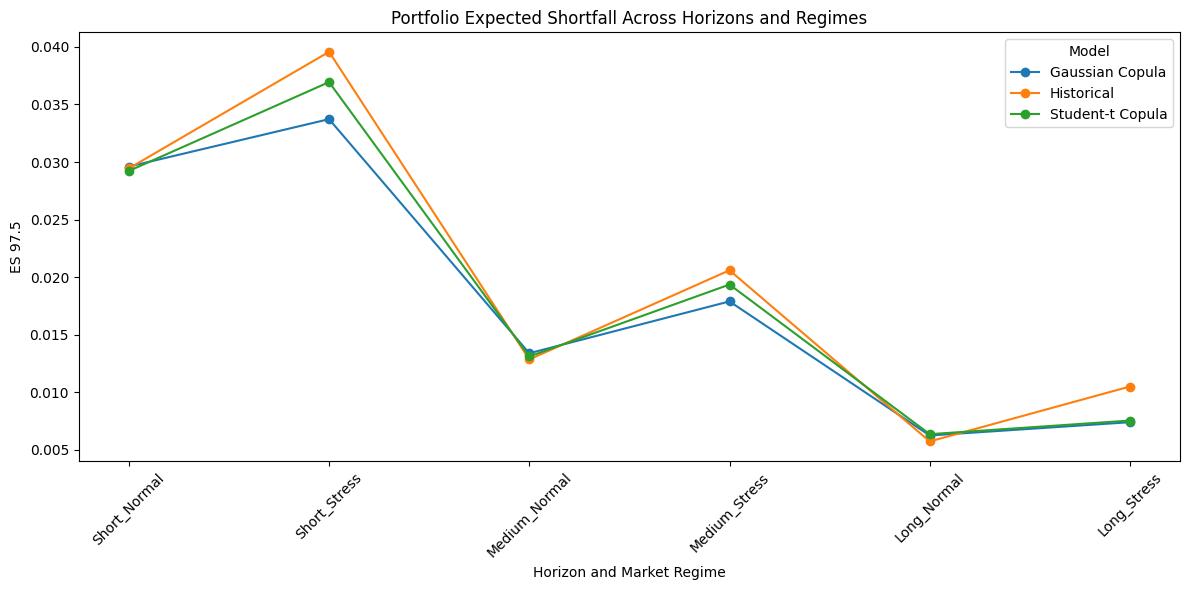

In [41]:
es_table.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title(
    "Portfolio Expected Shortfall Across Horizons and Regimes"
)

plt.xlabel(
    "Horizon and Market Regime"
)

plt.ylabel(
    "ES 97.5"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [42]:
var99_table = risk_comparison.pivot(
    index="Dataset",
    columns="Model",
    values="VaR_99"
)

var99_table = var99_table.reindex(
    dataset_order
)

var99_table

Model,Gaussian Copula,Historical,Student-t Copula
Dataset,,,
Short_Normal,0.028079,0.028625,0.028091
Short_Stress,0.031903,0.034265,0.034976
Medium_Normal,0.013824,0.012675,0.013168
Medium_Stress,0.017610,0.022494,0.019386
Long_Normal,0.006201,0.005852,0.006278
Long_Stress,0.007495,0.011475,0.007632


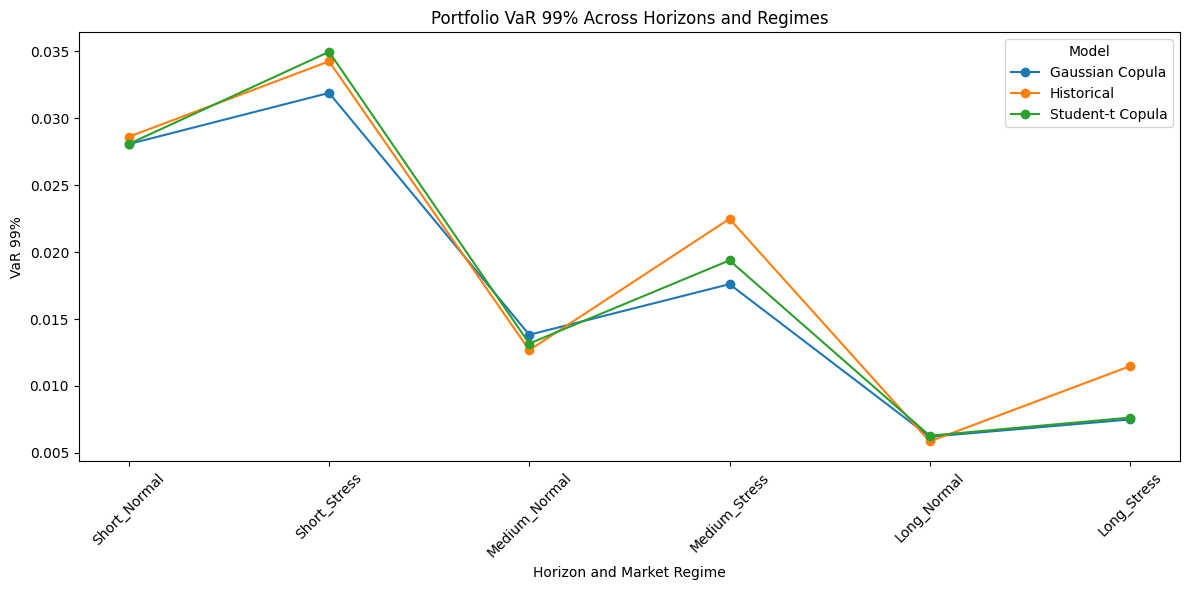

In [43]:
var99_table.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title(
    "Portfolio VaR 99% Across Horizons and Regimes"
)

plt.xlabel(
    "Horizon and Market Regime"
)

plt.ylabel(
    "VaR 99%"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [44]:
tail_model_difference = pd.DataFrame(
    index=es_table.index
)

tail_model_difference[
    "Gaussian_ES"
] = (
    es_table["Gaussian Copula"]
)

tail_model_difference[
    "Student_t_ES"
] = (
    es_table["Student-t Copula"]
)

tail_model_difference[
    "Absolute_Difference"
] = (
    tail_model_difference["Student_t_ES"]
    -
    tail_model_difference["Gaussian_ES"]
)

In [45]:
tail_model_difference[
    "Difference_Percent"
] = (
    tail_model_difference[
        "Absolute_Difference"
    ]
    /
    tail_model_difference[
        "Student_t_ES"
    ]
    * 100
)

tail_model_difference

,Gaussian_ES,Student_t_ES,Absolute_Difference,Difference_Percent
Dataset,,,,
Short_Normal,0.029602,0.029224,-0.000378,-1.292511
Short_Stress,0.033724,0.036940,0.003217,8.707768
Medium_Normal,0.013393,0.013114,-0.000278,-2.122871
Medium_Stress,0.017896,0.019360,0.001464,7.563621
Long_Normal,0.006251,0.006367,0.000116,1.816888
Long_Stress,0.007407,0.007550,0.000142,1.885078


In [46]:
stress_es_comparison = pd.DataFrame({
    
    "Normal": [
        es_table.loc[
            "Short_Normal",
            "Student-t Copula"
        ],
        
        es_table.loc[
            "Medium_Normal",
            "Student-t Copula"
        ],
        
        es_table.loc[
            "Long_Normal",
            "Student-t Copula"
        ]
    ],
    
    "Stress": [
        es_table.loc[
            "Short_Stress",
            "Student-t Copula"
        ],
        
        es_table.loc[
            "Medium_Stress",
            "Student-t Copula"
        ],
        
        es_table.loc[
            "Long_Stress",
            "Student-t Copula"
        ]
    ]
    
},
index=[
    "Short",
    "Medium",
    "Long"
])

stress_es_comparison

,Normal,Stress
Short,0.029224,0.03694
Medium,0.013114,0.01936
Long,0.006367,0.00755


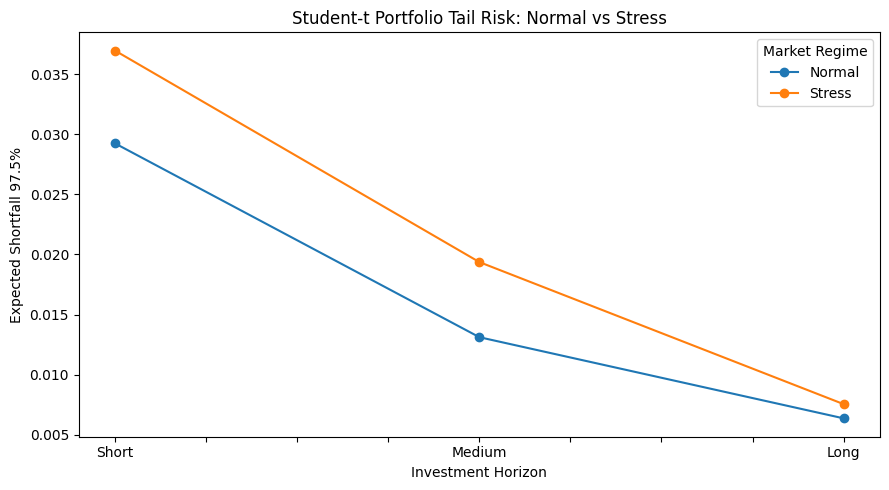

In [47]:
stress_es_comparison.plot(
    figsize=(9, 5),
    marker="o"
)

plt.title(
    "Student-t Portfolio Tail Risk: Normal vs Stress"
)

plt.xlabel(
    "Investment Horizon"
)

plt.ylabel(
    "Expected Shortfall 97.5%"
)

plt.legend(
    title="Market Regime"
)

plt.tight_layout()
plt.show()

In [48]:
stress_risk_ratio = pd.DataFrame(
    index=[
        "Short",
        "Medium",
        "Long"
    ]
)

stress_risk_ratio[
    "ES_Stress_to_Normal"
] = (
    stress_es_comparison["Stress"]
    /
    stress_es_comparison["Normal"]
)

stress_risk_ratiostress_risk_ratio = pd.DataFrame(
    index=[
        "Short",
        "Medium",
        "Long"
    ]
)

stress_risk_ratio[
    "ES_Stress_to_Normal"
] = (
    stress_es_comparison["Stress"]
    /
    stress_es_comparison["Normal"]
)

stress_risk_ratio

,ES_Stress_to_Normal
Short,1.264041
Medium,1.476302
Long,1.185835


In [49]:
historical_vs_t = pd.DataFrame({
    
    "Historical": (
        es_table["Historical"]
    ),
    
    "Student_t": (
        es_table["Student-t Copula"]
    )
})

historical_vs_t[
    "Difference"
] = (
    historical_vs_t["Student_t"]
    -
    historical_vs_t["Historical"]
)

historical_vs_t

,Historical,Student_t,Difference
Dataset,,,
Short_Normal,0.029446,0.029224,-0.000222
Short_Stress,0.039571,0.036940,-0.002630
Medium_Normal,0.012858,0.013114,0.000256
Medium_Stress,0.020600,0.019360,-0.001240
Long_Normal,0.005737,0.006367,0.000630
Long_Stress,0.010506,0.007550,-0.002956


In [50]:
historical_risk.to_csv(
    "outputs/tables/historical_portfolio_risk.csv",
    index=False
)

In [51]:
model_risk.to_csv(
    "outputs/tables/copula_portfolio_risk.csv",
    index=False
)

In [52]:
risk_comparison.to_csv(
    "outputs/tables/portfolio_risk_comparison.csv",
    index=False
)

In [53]:
t_nu_table.to_csv(
    "outputs/tables/multivariate_t_degrees_of_freedom.csv",
    index=False
)

In [54]:
tail_model_difference.to_csv(
    "outputs/tables/gaussian_vs_t_risk_difference.csv"
)

In [55]:
stress_risk_ratio.to_csv(
    "outputs/tables/stress_risk_amplification.csv"
)

In [56]:
print(
    "Notebook 08 completed successfully."
)

print(
    "\nPortfolio risk comparison:"
)

display(
    risk_display.round(3)
)

print(
    "\nStudent-t degrees of freedom:"
)

display(
    t_nu_table
)

print(
    "\nGaussian vs Student-t ES difference:"
)

display(
    tail_model_difference.round(4)
)

print(
    "\nStress risk amplification:"
)

display(
    stress_risk_ratio.round(3)
)

Notebook 08 completed successfully.

Portfolio risk comparison:


,Dataset,Model,VaR_95,VaR_99,ES_97.5
0,Short_Normal,Historical,1.596,2.863,2.945
1,Short_Stress,Historical,1.823,3.426,3.957
2,Medium_Normal,Historical,0.819,1.268,1.286
3,Medium_Stress,Historical,0.981,2.249,2.060
4,Long_Normal,Historical,0.457,0.585,0.574
5,Long_Stress,Historical,0.397,1.148,1.051
6,Short_Normal,Gaussian Copula,1.692,2.808,2.960
7,Short_Normal,Student-t Copula,1.649,2.809,2.922
8,Short_Stress,Gaussian Copula,1.944,3.190,3.372
9,Short_Stress,Student-t Copula,1.921,3.498,3.694



Student-t degrees of freedom:


,Dataset,nu
0,Short_Normal,13.0
1,Short_Stress,5.0
2,Medium_Normal,12.0
3,Medium_Stress,4.0
4,Long_Normal,9.0
5,Long_Stress,13.0



Gaussian vs Student-t ES difference:


,Gaussian_ES,Student_t_ES,Absolute_Difference,Difference_Percent
Dataset,,,,
Short_Normal,0.0296,0.0292,-0.0004,-1.2925
Short_Stress,0.0337,0.0369,0.0032,8.7078
Medium_Normal,0.0134,0.0131,-0.0003,-2.1229
Medium_Stress,0.0179,0.0194,0.0015,7.5636
Long_Normal,0.0063,0.0064,0.0001,1.8169
Long_Stress,0.0074,0.0075,0.0001,1.8851



Stress risk amplification:


,ES_Stress_to_Normal
Short,1.264
Medium,1.476
Long,1.186
